# 📊 Comprehensive Exploratory Data Analysis (EDA)
## CodeAlpha Internship — Task: Disease Prediction from Medical Data

### 1. Environment & Library Initialization

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [14]:
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")

### 2. Loading Medical Datasets

In [15]:
dataset = pd.read_csv('dataset.csv')
severity = pd.read_csv('Symptom-severity.csv')
description = pd.read_csv('symptom_Description.csv')
precaution = pd.read_csv('symptom_precaution.csv')

### 3. Data Structure & Dimension Audit

In [16]:
print(f"Main Dataset Dimensions:       {dataset.shape}")
print(f"Symptom Severity Dimensions:   {severity.shape}")
print(f"Disease Description Dimensions: {description.shape}")
print(f"Disease Precaution Dimensions:  {precaution.shape}")

Main Dataset Dimensions:       (4920, 18)
Symptom Severity Dimensions:   (133, 2)
Disease Description Dimensions: (41, 2)
Disease Precaution Dimensions:  (41, 5)


In [17]:
dataset.head(5)

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Disease     4920 non-null   str  
 1   Symptom_1   4920 non-null   str  
 2   Symptom_2   4920 non-null   str  
 3   Symptom_3   4920 non-null   str  
 4   Symptom_4   4572 non-null   str  
 5   Symptom_5   3714 non-null   str  
 6   Symptom_6   2934 non-null   str  
 7   Symptom_7   2268 non-null   str  
 8   Symptom_8   1944 non-null   str  
 9   Symptom_9   1692 non-null   str  
 10  Symptom_10  1512 non-null   str  
 11  Symptom_11  1194 non-null   str  
 12  Symptom_12  744 non-null    str  
 13  Symptom_13  504 non-null    str  
 14  Symptom_14  306 non-null    str  
 15  Symptom_15  240 non-null    str  
 16  Symptom_16  192 non-null    str  
 17  Symptom_17  72 non-null     str  
dtypes: str(18)
memory usage: 1.2 MB


### 4. Text Sanitization & String Standardization

In [19]:
severity['Symptom_clean'] = severity['Symptom'].str.strip().str.replace(' ', '')
severity_map = dict(zip(severity['Symptom_clean'], severity['weight']))

In [20]:
for col in dataset.columns:
    dataset[col] = dataset[col].astype(str).str.strip().str.replace(' ', '')
    dataset[col] = dataset[col].replace('nan', np.nan)

### 5. Disease Class Balance Audit

In [21]:
disease_counts = dataset['Disease'].value_counts()

In [22]:
print(f"Total Unique Disease Classes: {dataset['Disease'].nunique()}")
print(f"Minimum Samples per Class:    {disease_counts.min()}")
print(f"Maximum Samples per Class:    {disease_counts.max()}")

Total Unique Disease Classes: 41
Minimum Samples per Class:    120
Maximum Samples per Class:    120


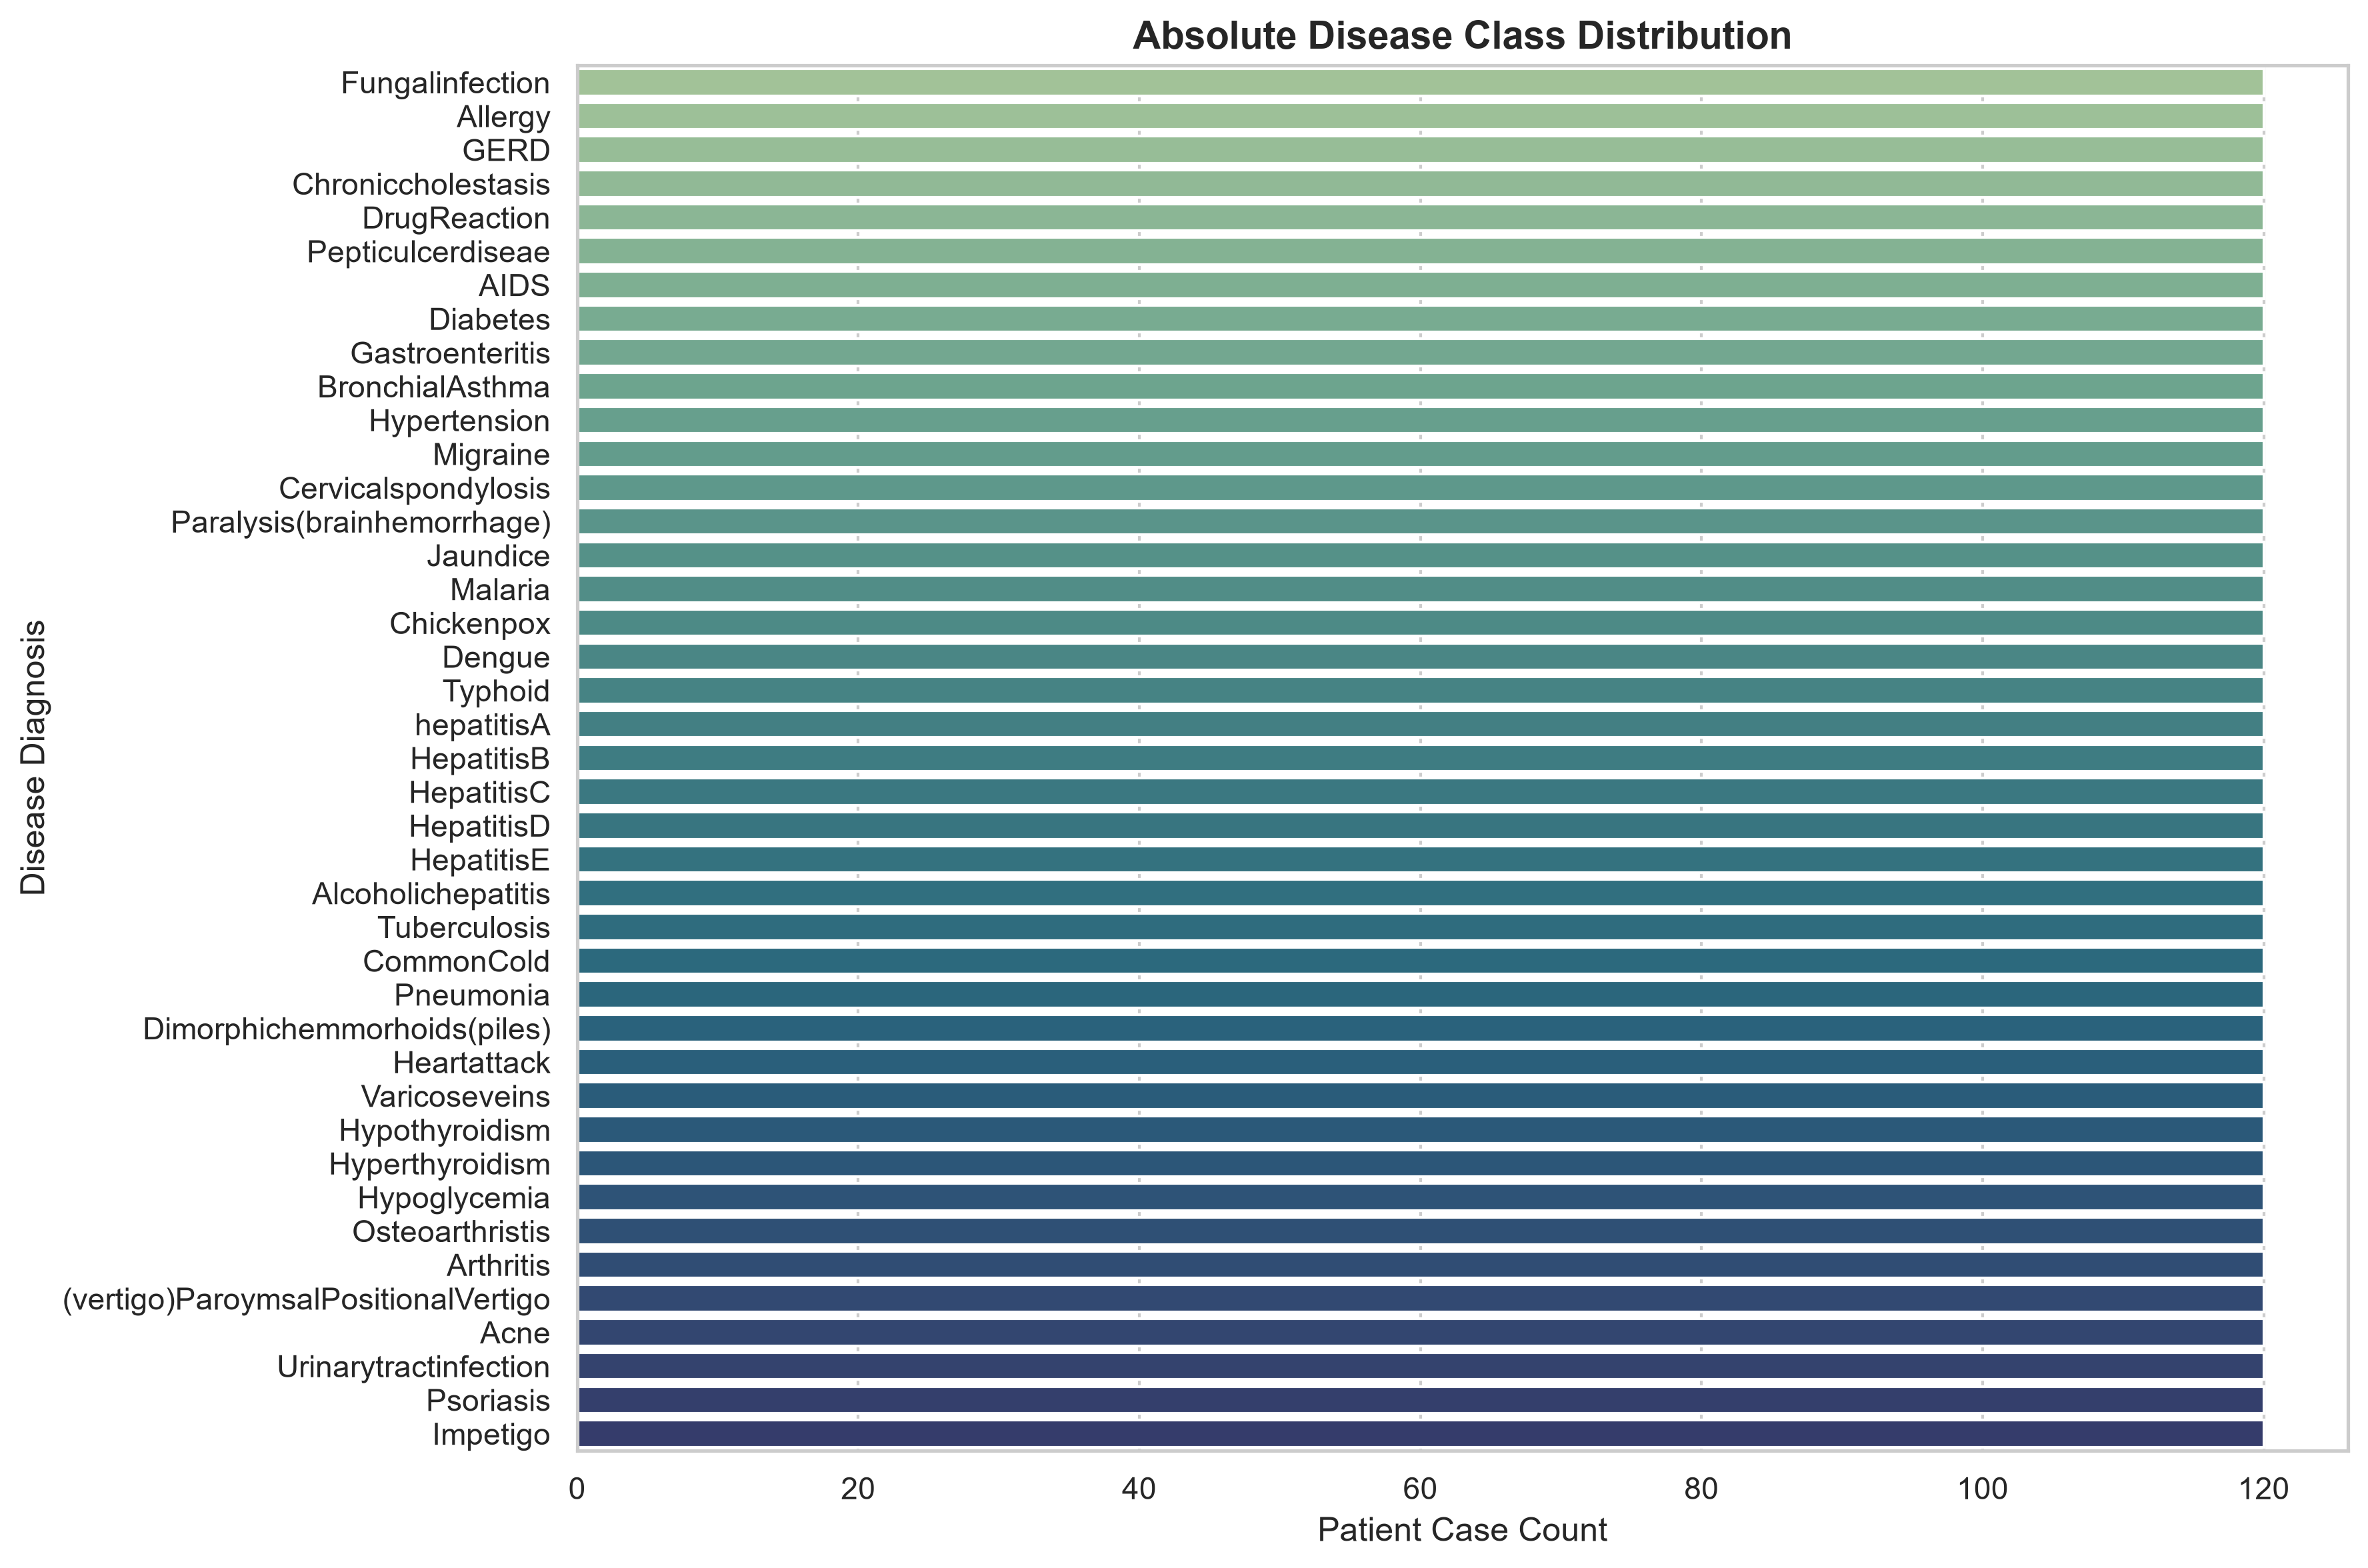

In [23]:
plt.figure(figsize=(12, 8))
sns.barplot(
    x=disease_counts.values, 
    y=disease_counts.index, 
    hue=disease_counts.index, 
    palette='crest', 
    legend=False
)
plt.title('Absolute Disease Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Patient Case Count')
plt.ylabel('Disease Diagnosis')
plt.tight_layout()
plt.show()

### 6. Symptom Density per Patient Record

In [24]:
symptom_cols = [c for c in dataset.columns if c != 'Disease']
patient_symptom_counts = dataset[symptom_cols].notna().sum(axis=1)

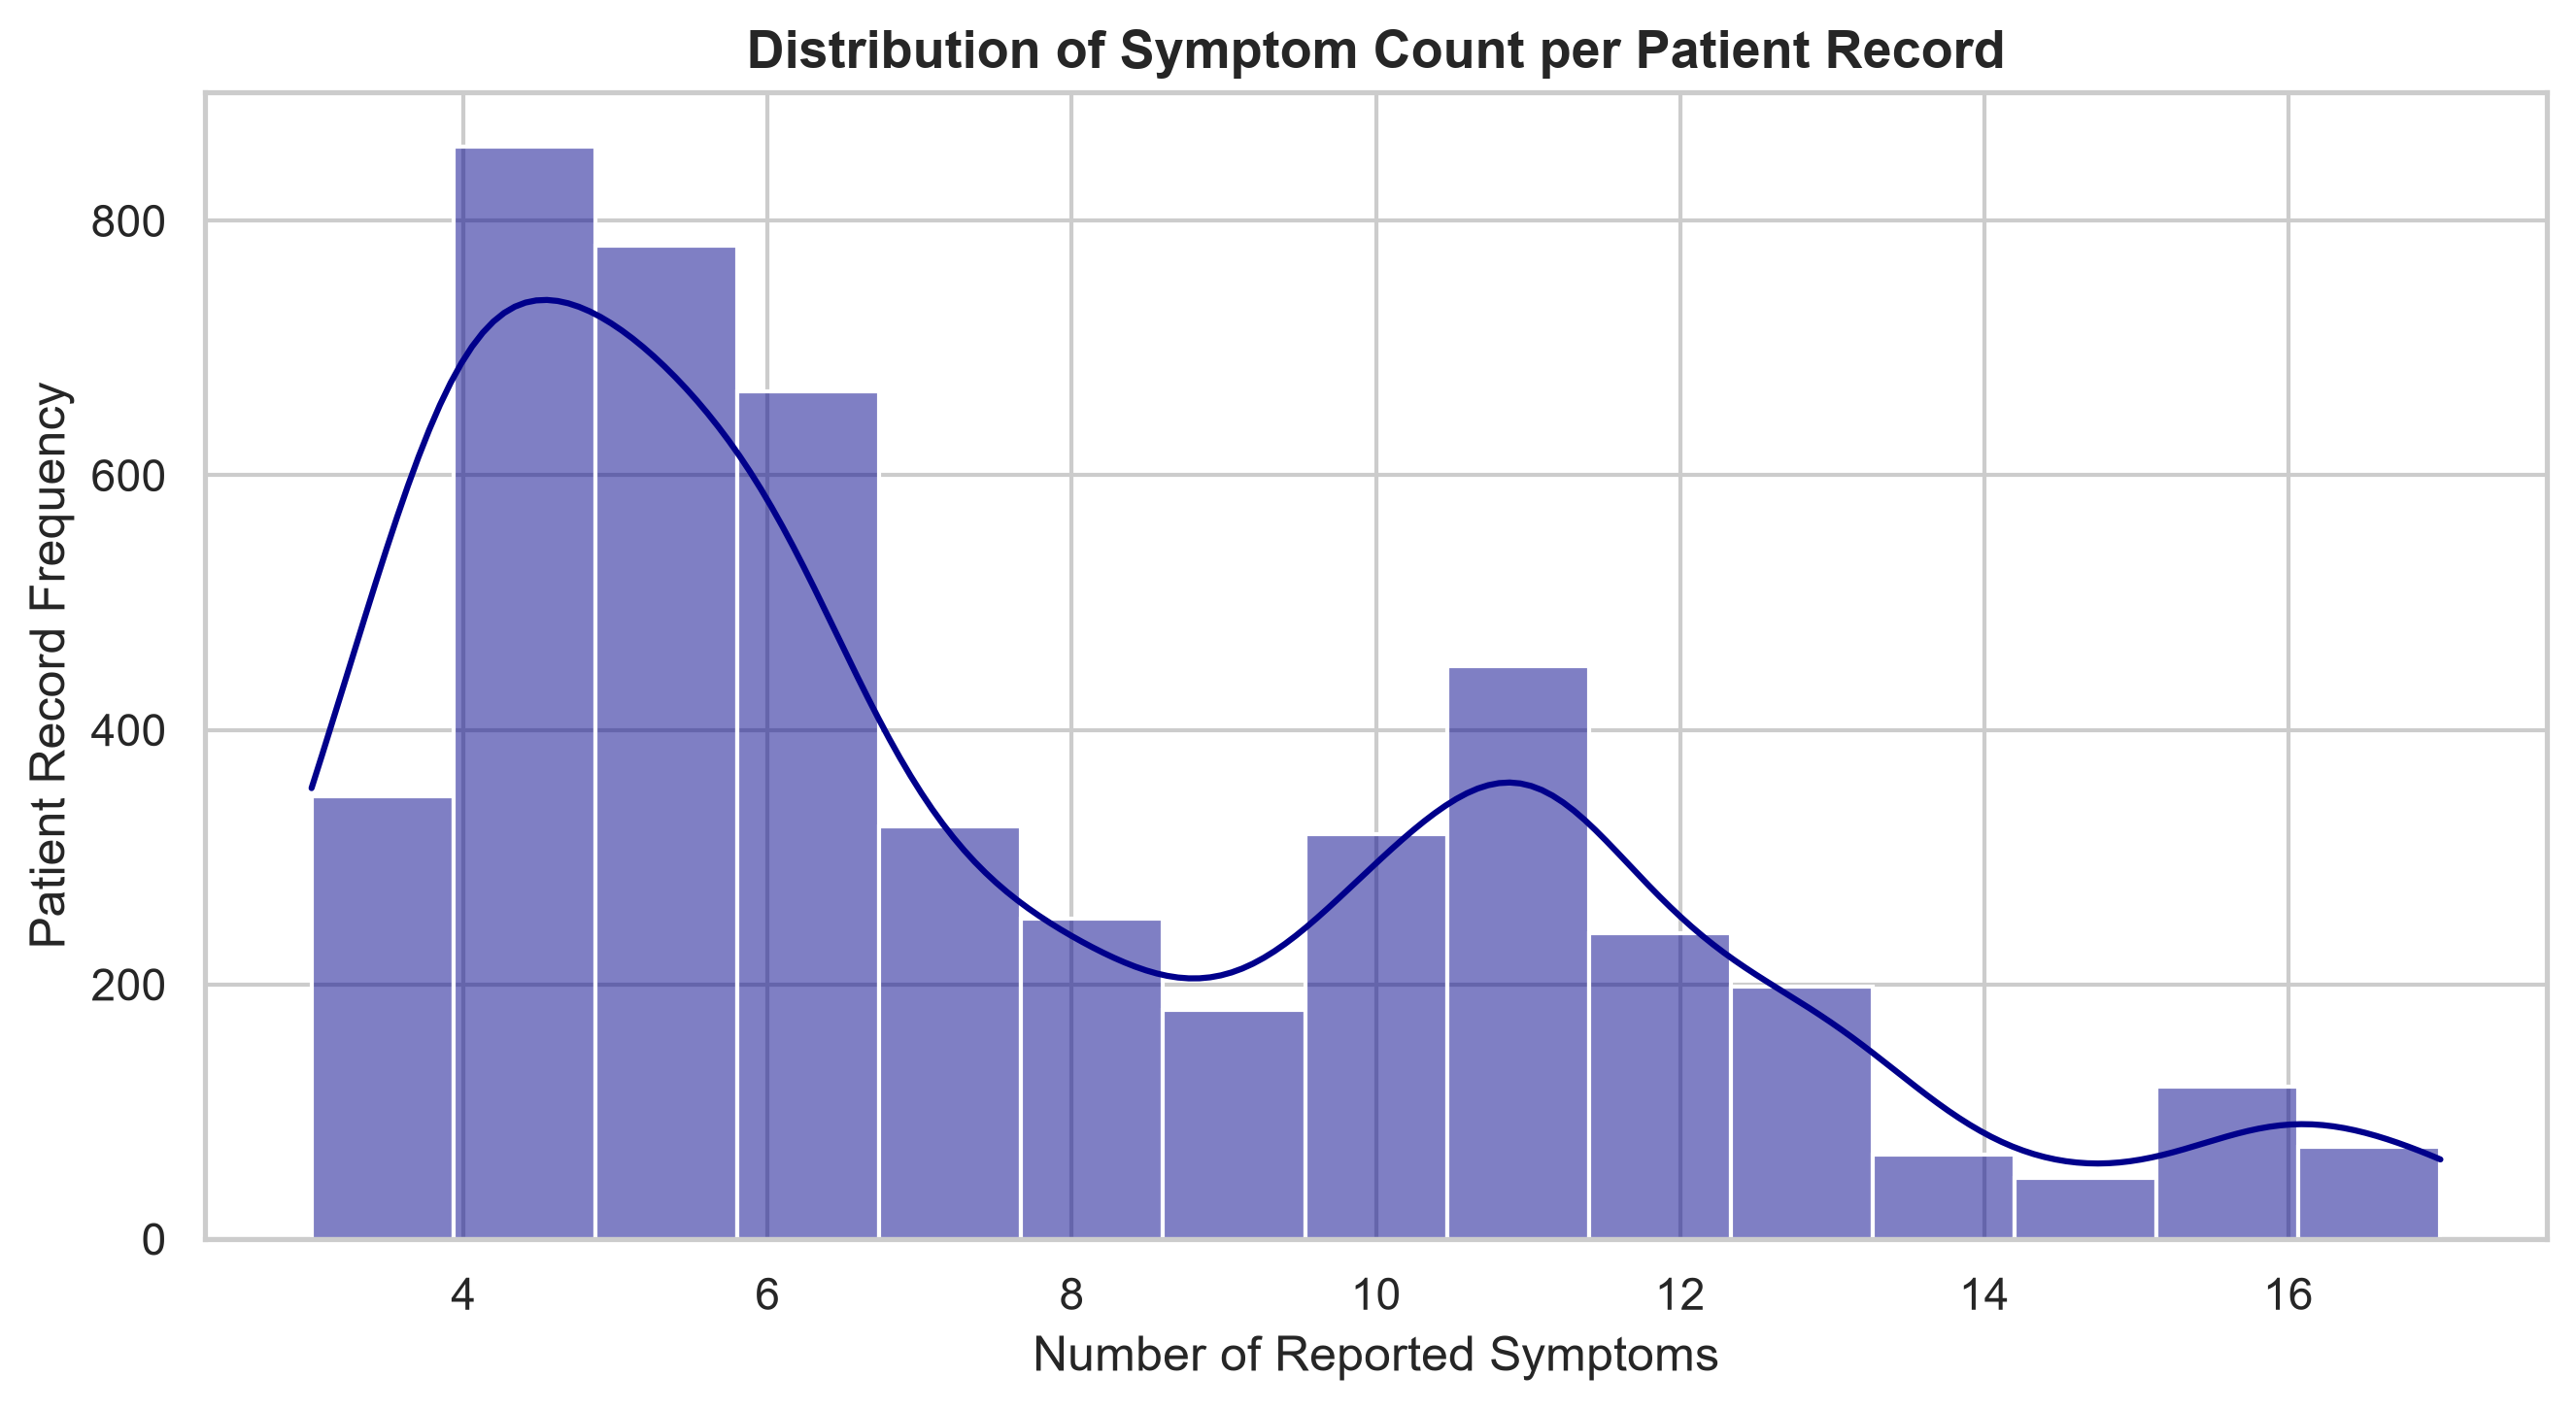

In [25]:
plt.figure(figsize=(9, 5))
sns.histplot(patient_symptom_counts, bins=15, kde=True, color='darkblue')
plt.title('Distribution of Symptom Count per Patient Record', fontsize=13, fontweight='bold')
plt.xlabel('Number of Reported Symptoms')
plt.ylabel('Patient Record Frequency')
plt.tight_layout()
plt.show()

### 7. Unique Symptoms Frequency Analysis

In [26]:
all_reported_symptoms = dataset[symptom_cols].values.flatten()
symptom_series = pd.Series([s for s in all_reported_symptoms if pd.notna(s)])
top_symptoms = symptom_series.value_counts().head(20)

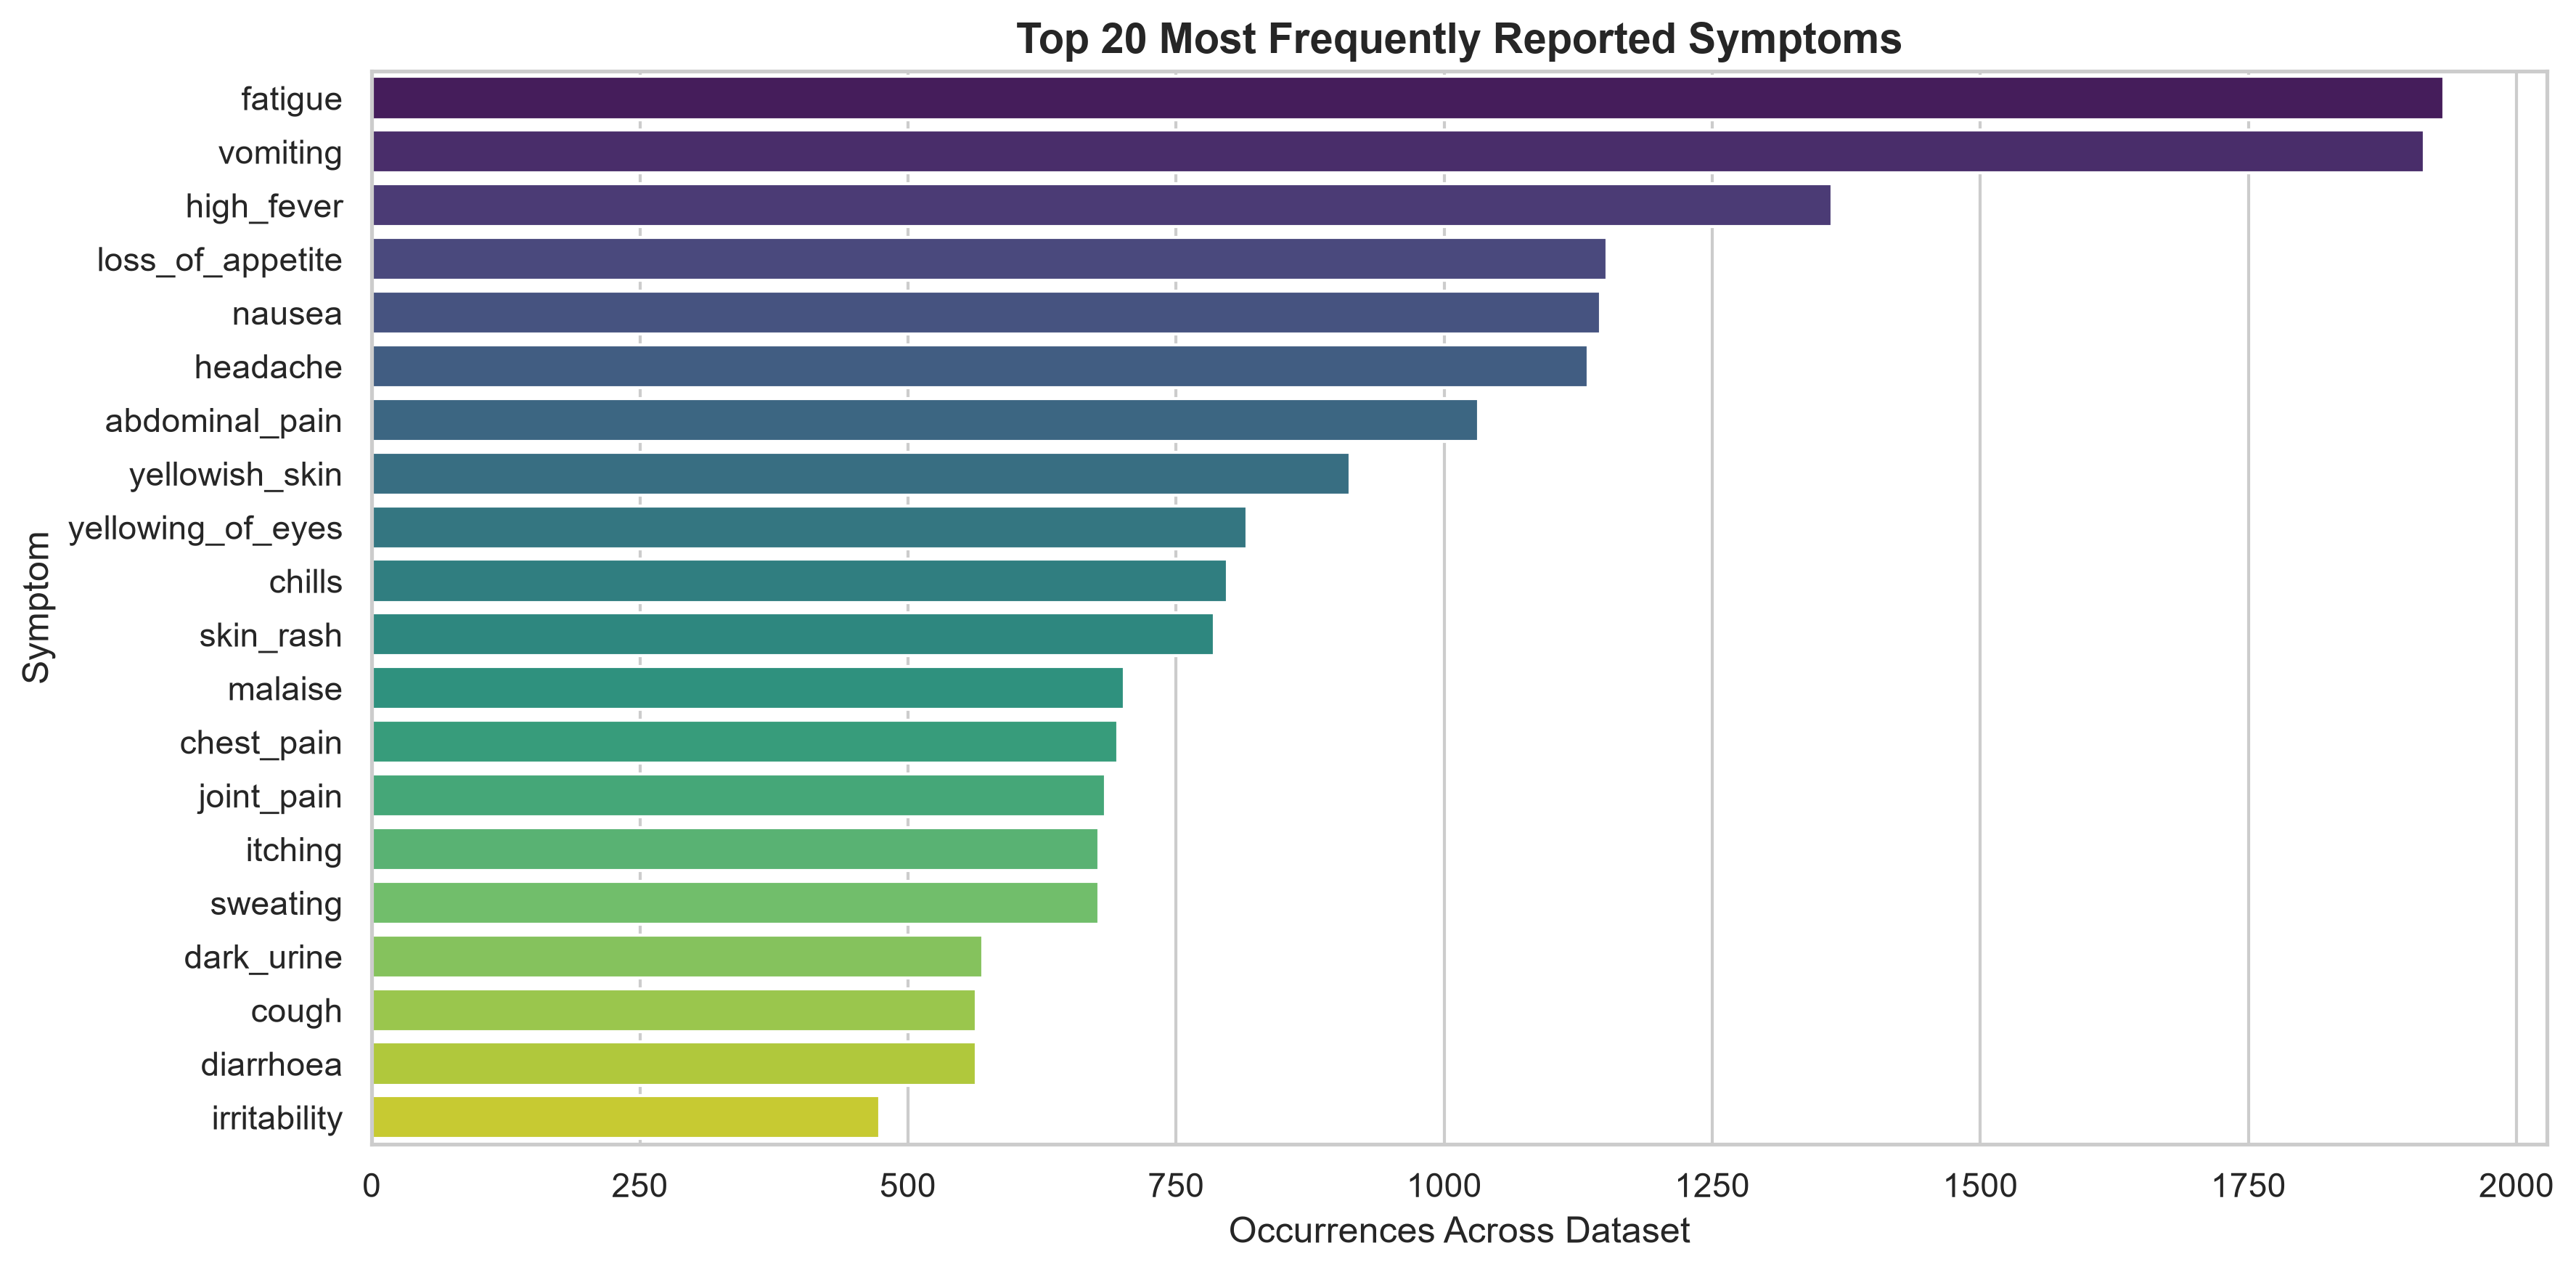

In [27]:
plt.figure(figsize=(12, 6))
sns.barplot(x=top_symptoms.values, y=top_symptoms.index, palette='viridis')
plt.title('Top 20 Most Frequently Reported Symptoms', fontsize=14, fontweight='bold')
plt.xlabel('Occurrences Across Dataset')
plt.ylabel('Symptom')
plt.tight_layout()
plt.show()

### 8. Symptom Severity Weight Profile

In [28]:
top_severity = severity.sort_values(by='weight', ascending=False).head(15)

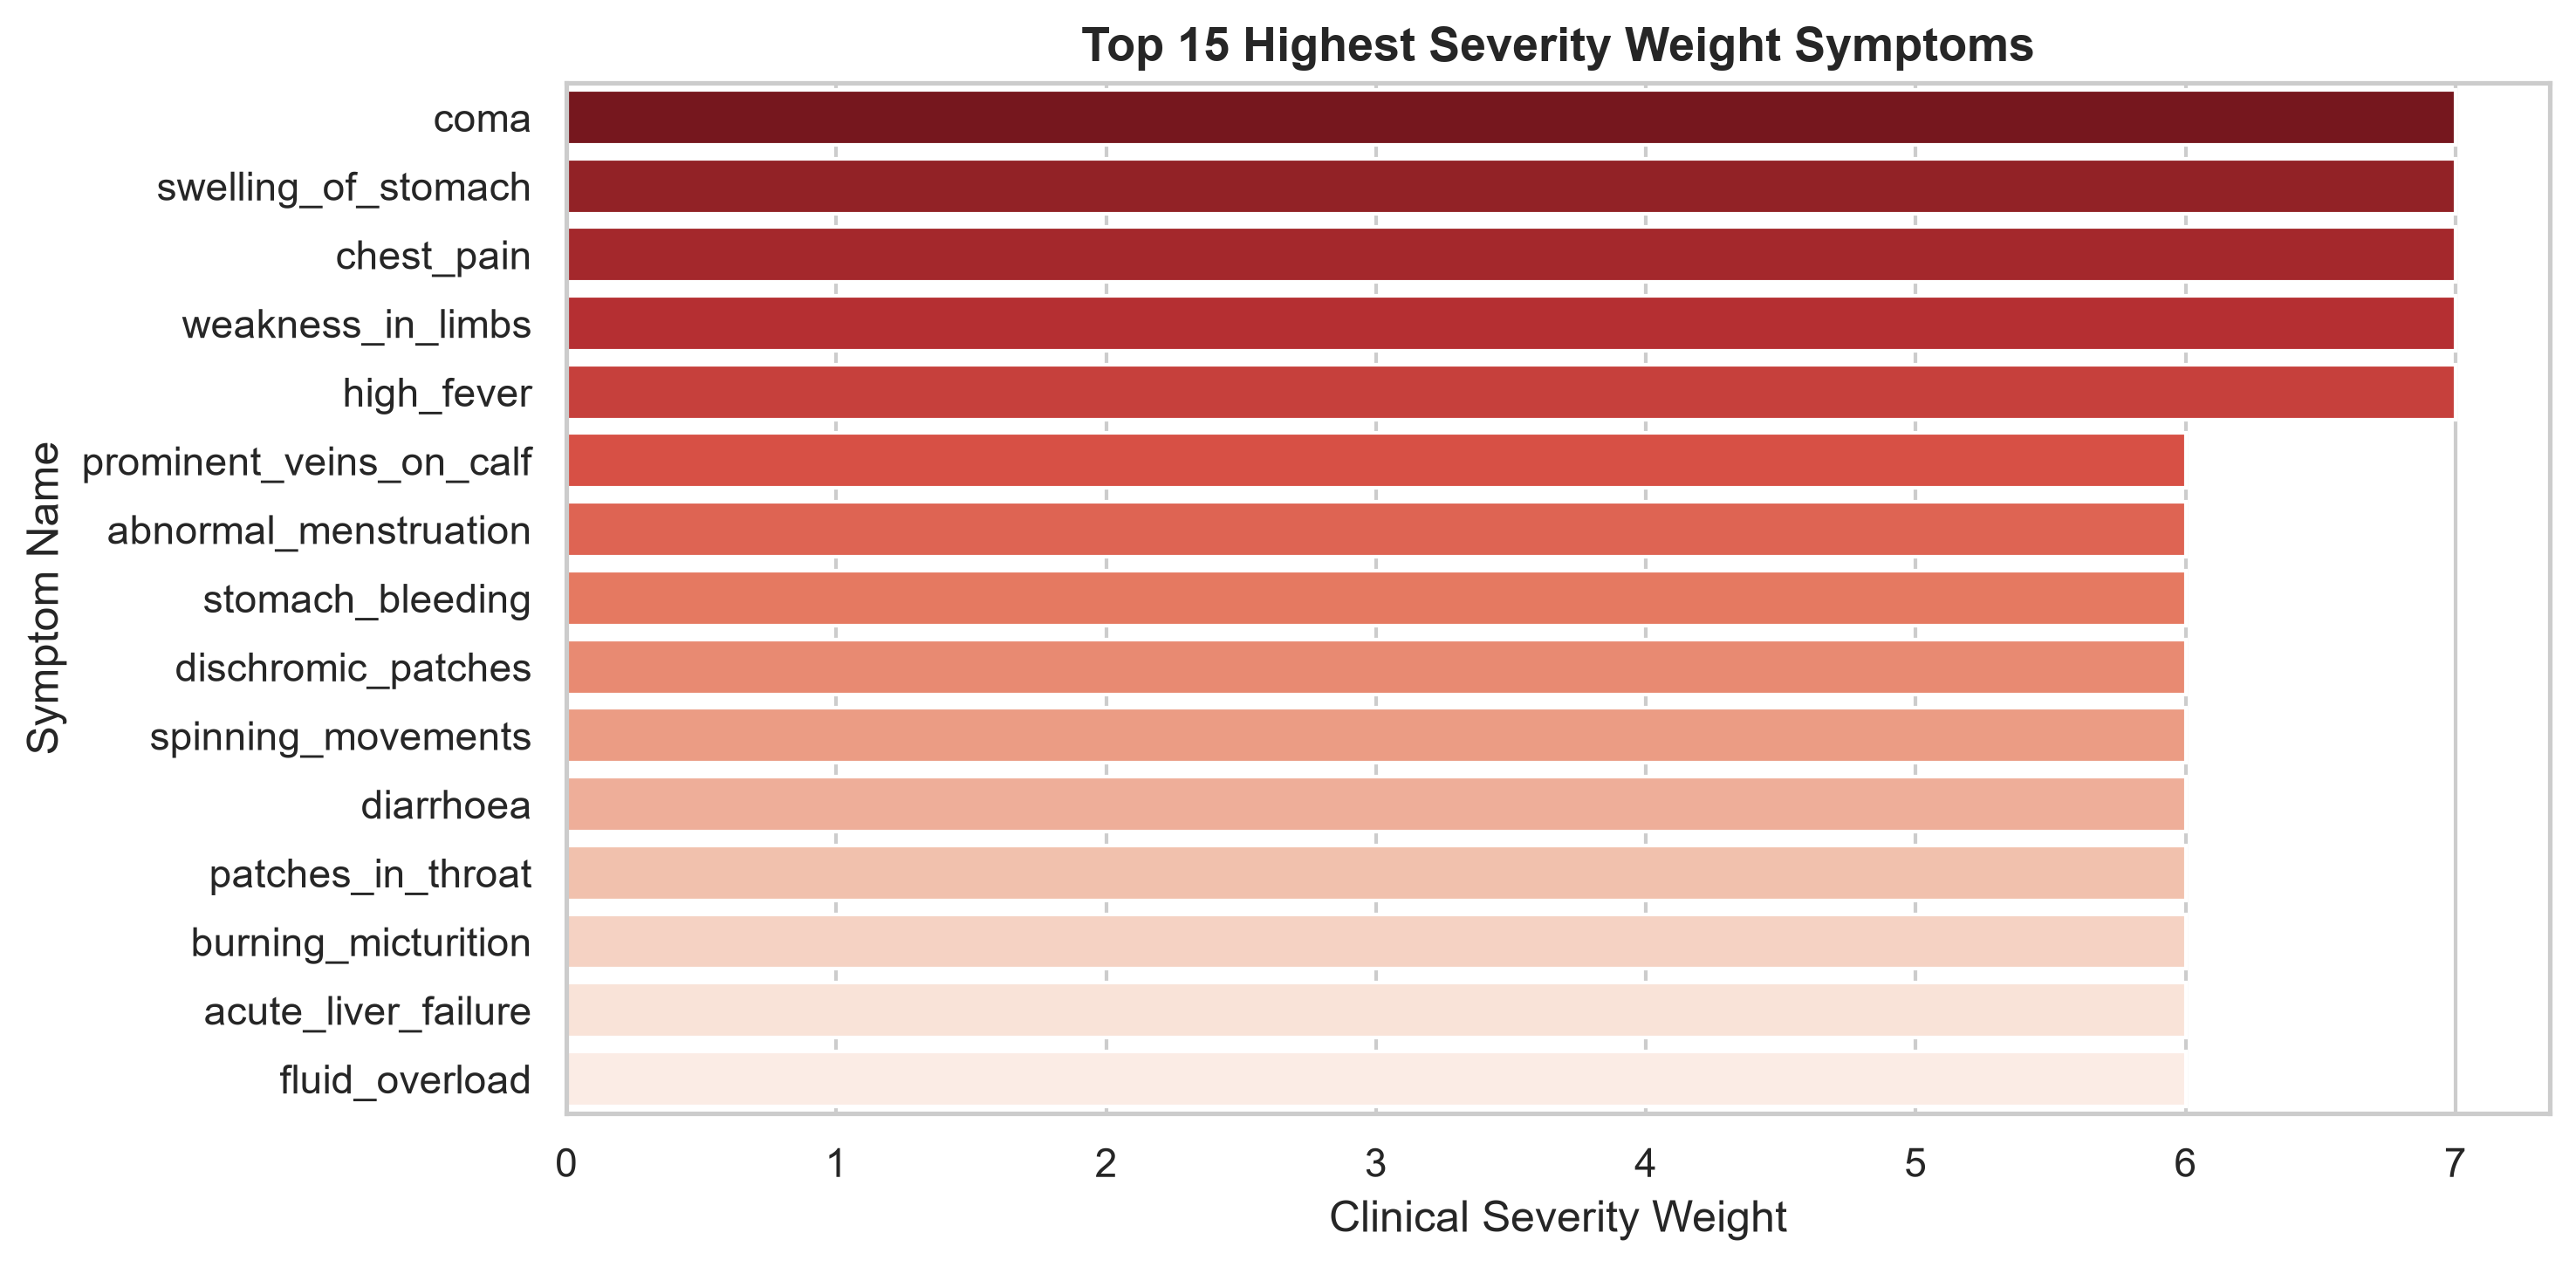

In [29]:
plt.figure(figsize=(10, 5))
sns.barplot(x='weight', y='Symptom_clean', data=top_severity, palette='Reds_r')
plt.title('Top 15 Highest Severity Weight Symptoms', fontsize=13, fontweight='bold')
plt.xlabel('Clinical Severity Weight')
plt.ylabel('Symptom Name')
plt.tight_layout()
plt.show()

### 9. Cumulative Symptom Severity per Disease

In [30]:
def calculate_row_severity(row):
    total_weight = 0
    for sym in row[symptom_cols]:
        if pd.notna(sym) and sym in severity_map:
            total_weight += severity_map[sym]
    return total_weight

In [31]:
dataset['Severity_Score'] = dataset.apply(calculate_row_severity, axis=1)
disease_severity = dataset.groupby('Disease')['Severity_Score'].mean().sort_values(ascending=False).head(15)

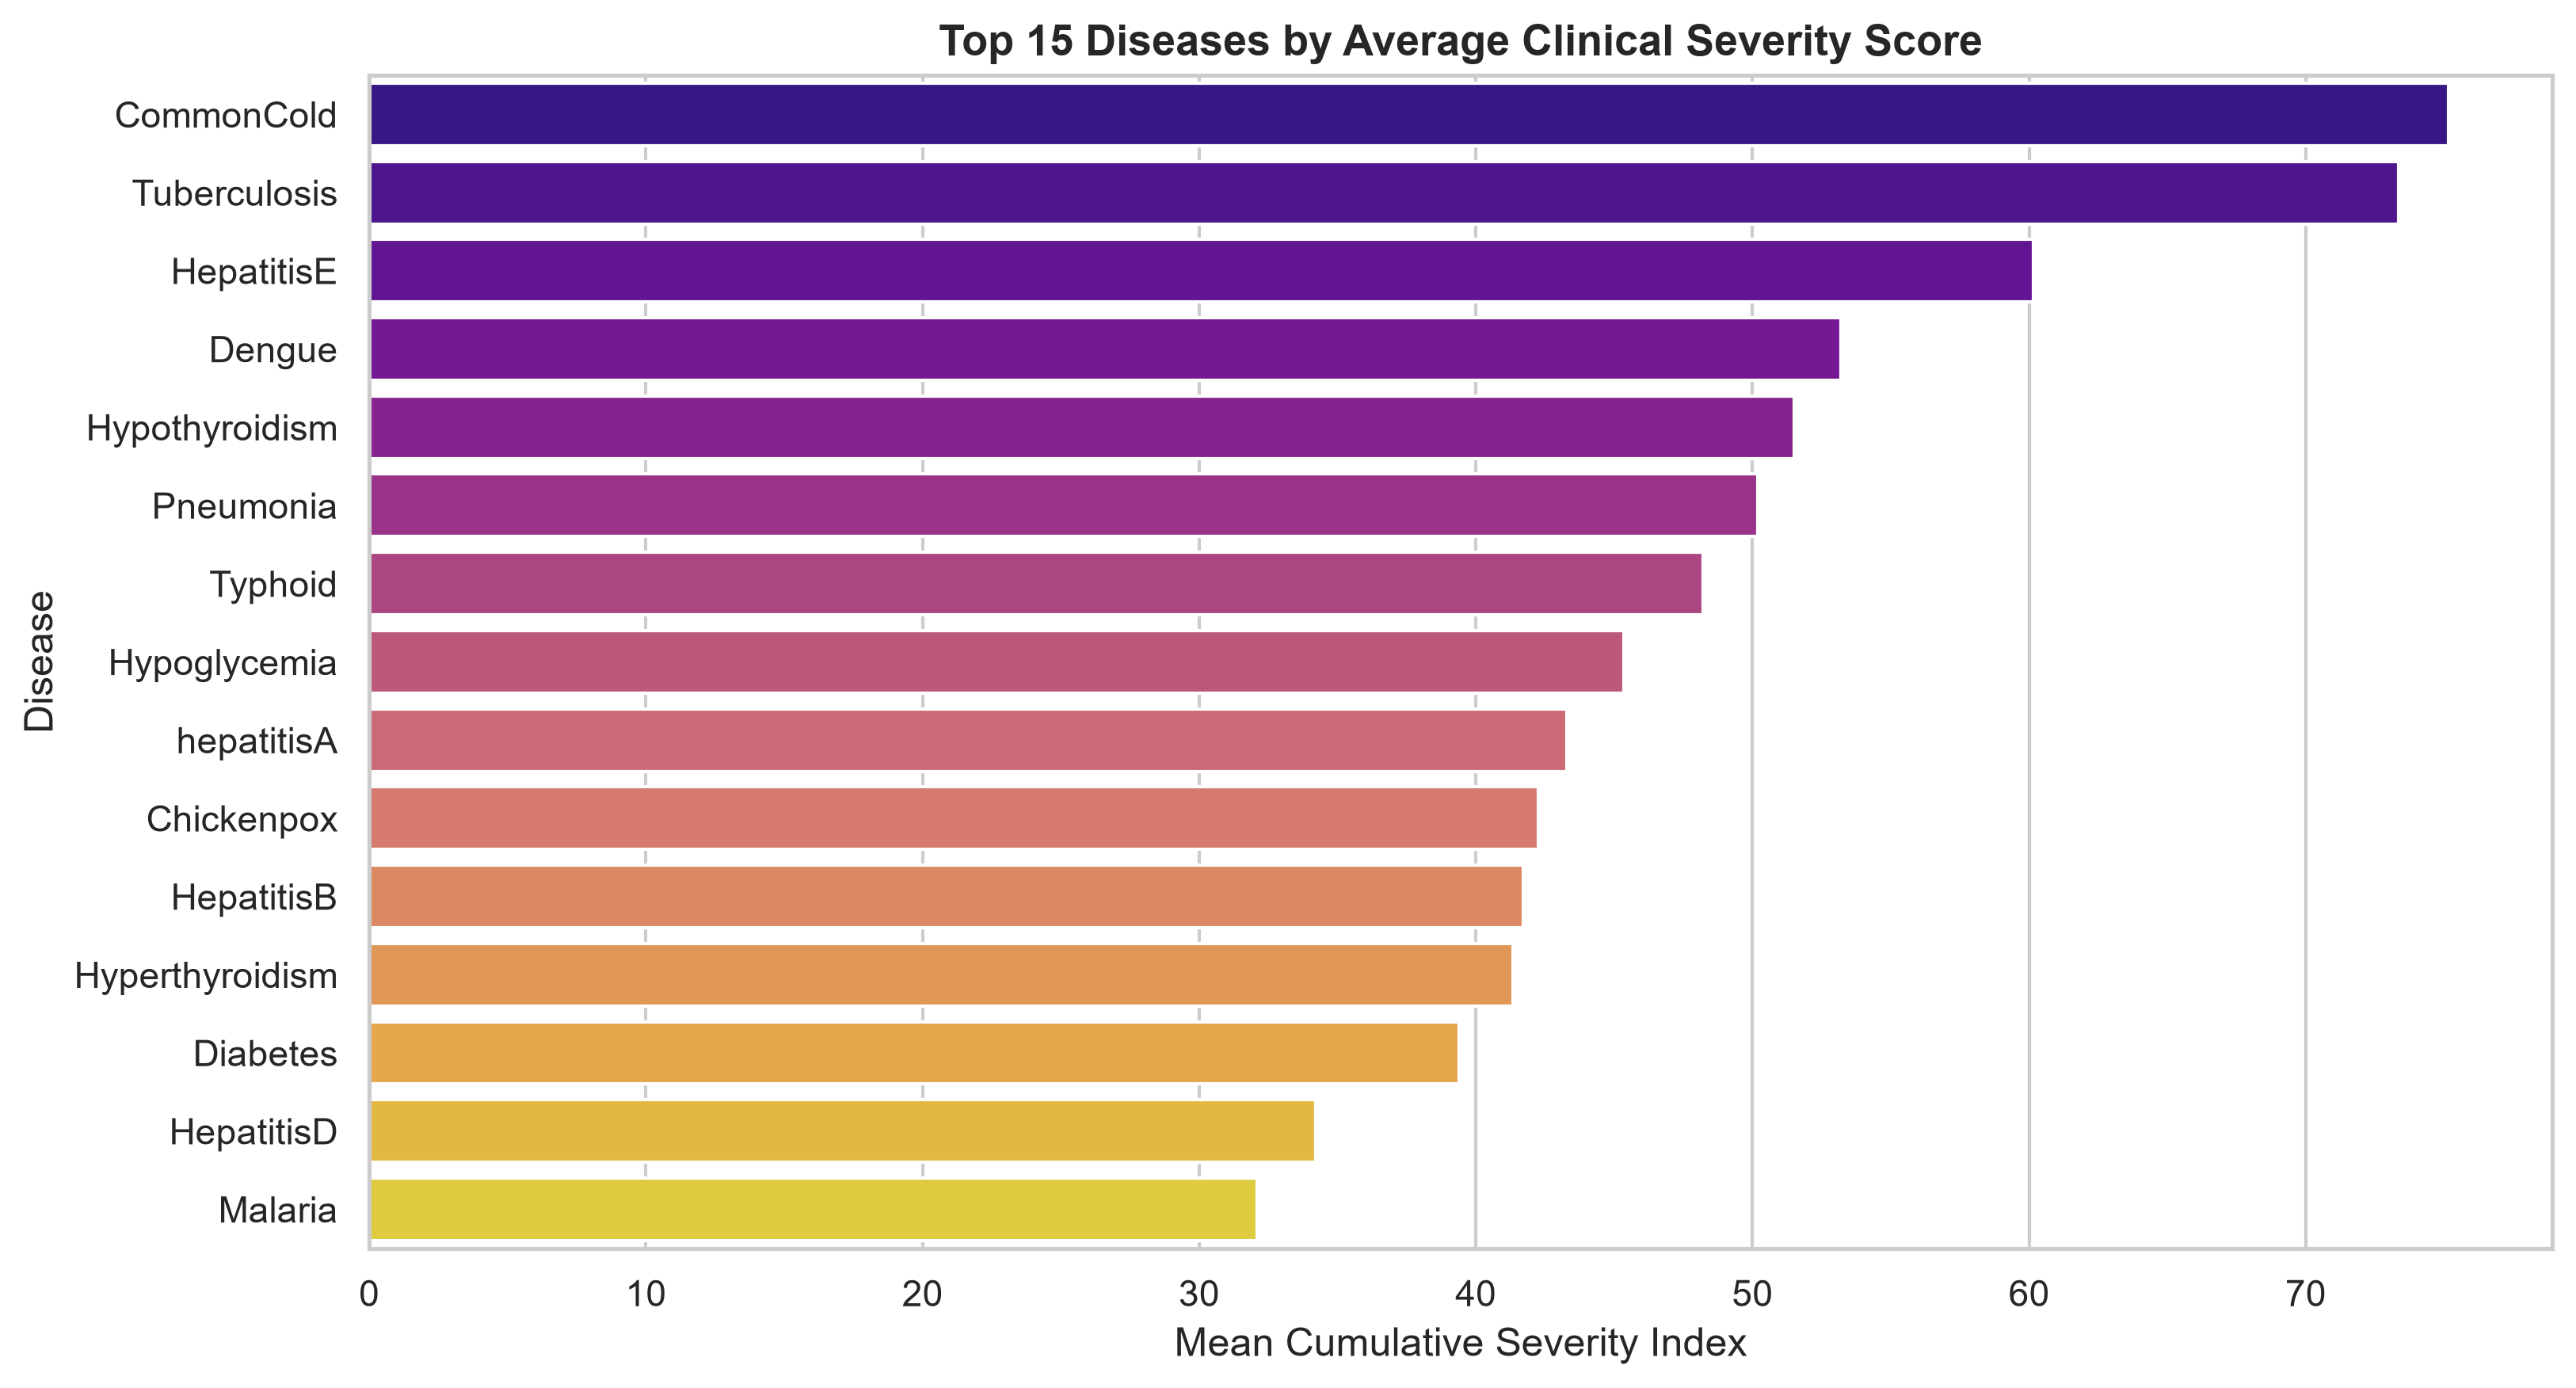

In [32]:
plt.figure(figsize=(11, 6))
sns.barplot(x=disease_severity.values, y=disease_severity.index, palette='plasma')
plt.title('Top 15 Diseases by Average Clinical Severity Score', fontsize=13, fontweight='bold')
plt.xlabel('Mean Cumulative Severity Index')
plt.ylabel('Disease')
plt.tight_layout()
plt.show()

### 10. Symptom Co-Occurrence Heatmap Analysis

In [33]:
top_10_symptoms = top_symptoms.index[:10]
binary_matrix_10 = pd.DataFrame(0, index=dataset.index, columns=top_10_symptoms)
for col in symptom_cols:
    for sym in top_10_symptoms:
        binary_matrix_10[sym] = binary_matrix_10[sym] | (dataset[col] == sym).astype(int)

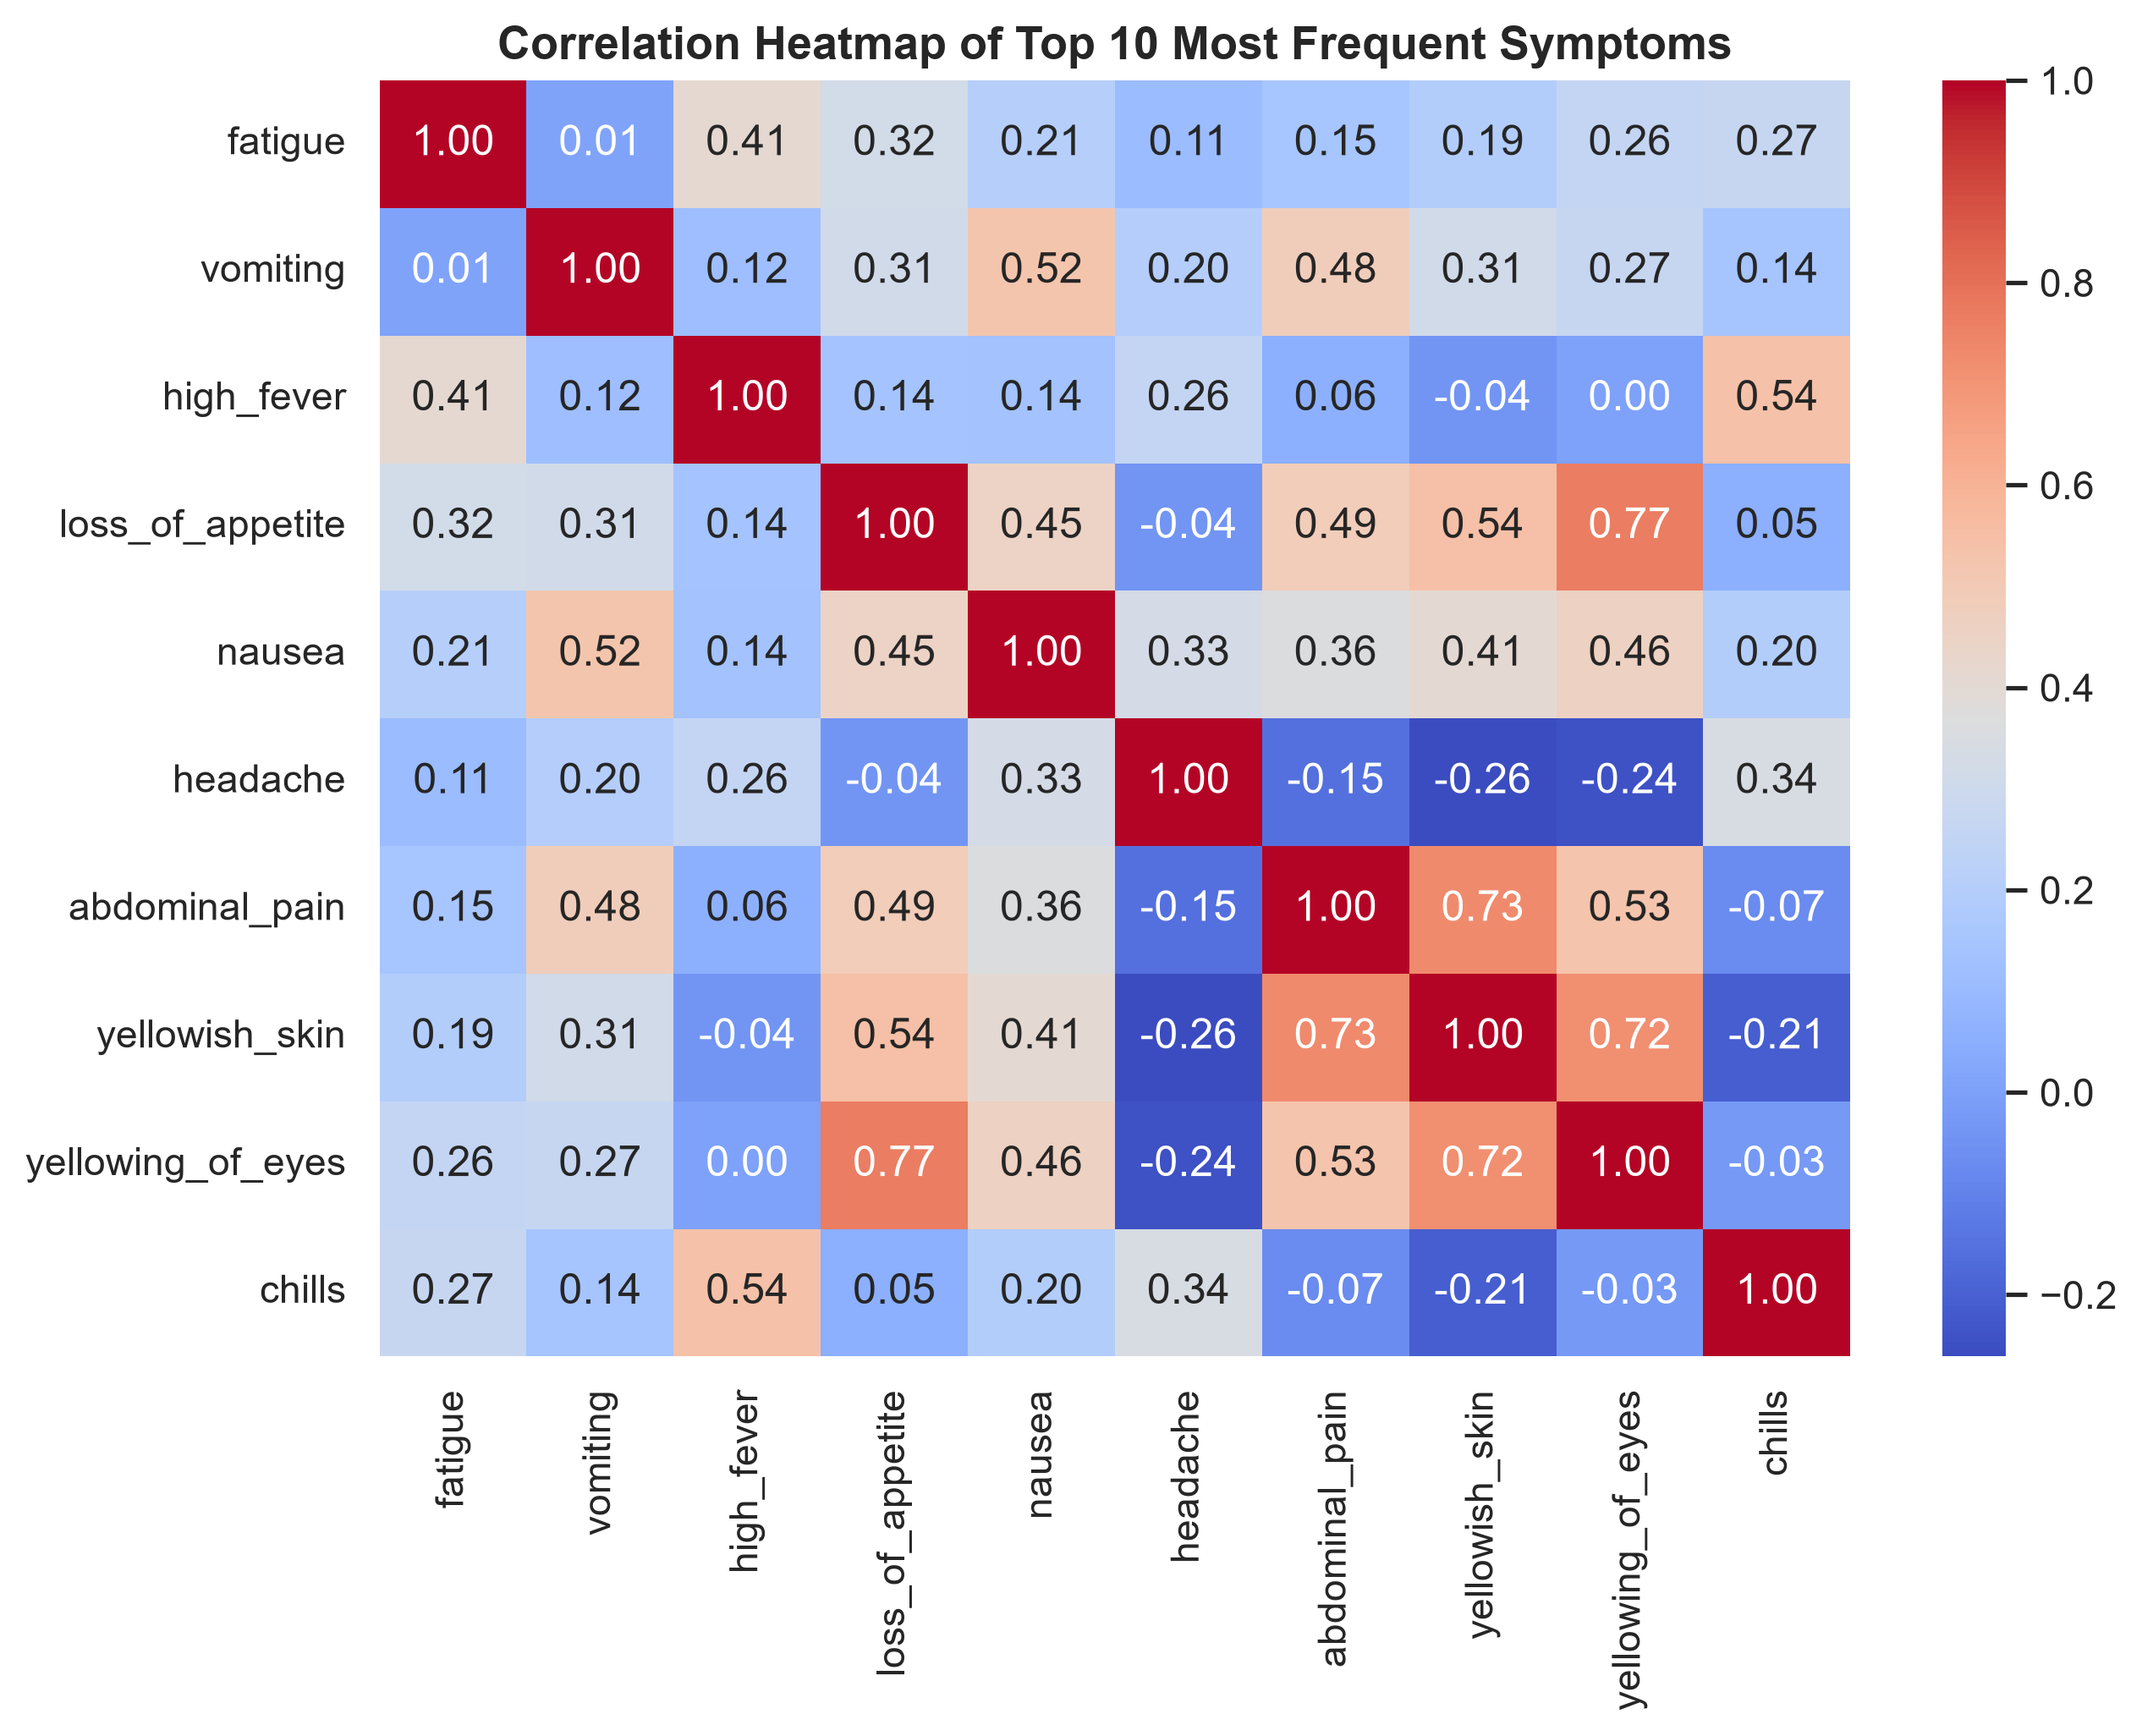

In [34]:
plt.figure(figsize=(9, 7))
sns.heatmap(binary_matrix_10.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Top 10 Most Frequent Symptoms', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()